# Temperature Climate Normals

This notebook serves for the Temperature Climate Normal computation:
1. horizontal resolution = 0.125 sexagesimal degrees;
2. MED box: lon = [-9.25 36.5] degrees E, lat = [30 46] degrees N;
3. WOA 2018 102 depth levels;
4. merged temperature only input dataset from SDC V2 and CORA V52 vertically interpolated to WOA 2018 depth layers written in DIVAnd input format (final version with removed outliers and duplicates);
5. Time range 1955-2018, sliding decades annual analysis;
6. Bathymetry from GEBCO 15 arc second 2019 and mask “gebco_2019_mask_1_8_edited_final.nc” edited opening and closing numerous zones and with removed less than 3 points connected components;
7. Horizontal background correlation length of Approx 5.5 degrees;
8. Vertical correlation length equal to zero (communications and update with A. Barth);
9. Background average vertical correlation equal to layer thickness;
10. Background epsilon2 = 12;
11. filteranom = 0 (communication with A. Barth);
12. surfextend = false (communication with A. Barth);
13. epsilon2 = 6;
14. Saving residuals;
15. Horizontal correlation length of Approx 2 degrees;
16. Analysis niter_e = 1;
17. External mask loaded from netCDF.

In [1]:
#import Pkg

#Pkg.add("PyPlot")
#Pkg.add("NCDatasets")
#Pkg.add("DataStructures")
#Pkg.add("Compat")
#Pkg.add("PhysOcean")
#Pkg.add("DIVAnd")

In [2]:
using DIVAnd
#using PythonPlot
using PyPlot
using NCDatasets
if VERSION >= v"0.7.0-beta.0"
    using Dates
    using Statistics
else
    using Compat: @info, @warn, @debug
end
using Compat

using PhysOcean
using DataStructures
if VERSION >= v"0.7.0-beta.0"
    using Dates
    using Statistics
    using Random
    using Printf
else
    using Compat: @info, @warn, @debug
end

## Metadata

In [3]:
project = "SeaDataCloud";
institution_urn = "SDN:EDMO::251";
in_variable_name = "Temperature";
production = "INGV oceanography group. Emails: paolo.oliveri@ingv.it; simona.simoncelli@ingv.it; gelsomina.mattia@ingv.it";
author_email = ["Enrico Baglione <enrico.baglione@ingv.it>", "Simona Simoncelli <simona.simoncelli@ingv.it", "Paolo Oliveri <paolo.oliveri@ingv.it>"];
source = "observational data from SeaDataNet, CORA 5.2";
comment = "Duplicates removal and QC applied to the integrated dataset";
parameter_keyword_urn = "SDN:P35::WATERTEMP";
search_keywords_urn = "SDN:P02::TEMP";
area_keywords_urn = "SDN:C19::3_1";
product_version = "1.0";
product_code = "SDC_MED_DP2";
bathymetry_source = "The GEBCO Digital Atlas published by the British Oceanographic Data Centre on behalf of IOC and IHO, 2003";
standard_name = "sea_water_temperature";
long_name = "Sea Water In Situ Temperature";
units = "degree_C";
abstract_name = "SDC_MED_DP2 product contains Temperature annual sliding climatological field and Area Averaged Ocean Heat Content Anomaly. The climatological field has been computed from SeaDataNet infrastructure and CORA (Coriolis Ocean dataset for ReAnalysis) integrated dataset using the DIVAnd (Data-Interpolating Variational Analysis in n dimensions) version 2.6.1";
acknowledgement = "EC H2020 grant #730960 SeaDataCloud";
documentation = "http://dx.doi.org/doi_of_doc";
doi = "https://doi.org/10.12770/504ea4ee-abee-4ebf-ab89-c4200e1cdad4";

## Data reading
Observations are read from SDC V1 and CORA V52 vertically interpolated to WOA 2018 depth layers dataset.
The reading is done using `loadobs` function.

#### PATHS TO INDICATE FOR THE WOD NORMALS #########
- 1971-2000: /storage/10GE_nfs/ambiente/oceano/OceanStory/enrico.baglione/2025_CLIMATE_NORMALS_1971_2000/
- 1981-2010: /storage/10GE_nfs/ambiente/oceano/OceanStory/enrico.baglione/2025_CLIMATE_NORMALS_1981_2010/
- 1991-2020: /storage/10GE_nfs/ambiente/oceano/OceanStory/enrico.baglione/2025_CLIMATE_NORMALS_1991_2020/

#### PATHS TO INDICATE FOR THE SDC NORMALS #########
- 1971-2000: /storage/10GE_nfs/ambiente/oceano/OceanStory/enrico.baglione/2025_SDC_NORMALS_1971_2000/
- 1981-2010: /storage/10GE_nfs/ambiente/oceano/OceanStory/enrico.baglione/2025_SDC_NORMALS_1981_2010/

#### PATHS TO INDICATE FOR THE IQUOD LINEAR NORMALS #########
- 1971-2000: /storage/10GE_nfs/ambiente/oceano/OceanStory/enrico.baglione/2025_IQUOD/2025_IQUOD_LINEAR/2025_IQUOD_LINEAR_NORM_1971_2000/
- 1981-2010: /storage/10GE_nfs/ambiente/oceano/OceanStory/enrico.baglione/2025_IQUOD/2025_IQUOD_LINEAR/2025_IQUOD_LINEAR_NORM_1981_2010/

#### PATHS TO INDICATE FOR THE CORA NORMALS #########
- 1971-2000: /storage/10GE_nfs/ambiente/oceano/OceanStory/enrico.baglione/INPUT_OUTPUT/2026_CORA_NORMALS_1971_2000/
- 1981-2010: /storage/10GE_nfs/ambiente/oceano/OceanStory/enrico.baglione/INPUT_OUTPUT/2026_CORA_NORMALS_1981_2010/
- 1991-2020: /storage/10GE_nfs/ambiente/oceano/OceanStory/enrico.baglione/INPUT_OUTPUT/2026_CORA_NORMALS_1991_2020/

In [4]:
#program_name = "production_SDC_NORMALS 1971"  # Change this to your program's actual name
program_name = "production_MOW_Box"  # Change this to your program's actual name
#log_file = "execution_time_SDC_NORMAL_1971.log"
log_file = "execution_time_MOW_Box.log"

"execution_time_MOW_Box.log"

In [5]:
@info "Please give base data directory..."

base_dir = readline(stdin)

in_variable_name = "TEMPERATURE";

# /storage/10GE_nfs/ambiente/oceano/OceanStory/enrico.baglione/2025_SDC_NORMALS_1981_2010/
# /storage/10GE_nfs/ambiente/oceano/OceanStory/enrico.baglione/2025_SDC_NORMALS_1971_2000/

bathymetry_file = "/storage/10GE_nfs/ambiente/oceano/Climatologie/SeaDataCloud/Bathymetry/GEBCO_2019_cut_atl_renamed.nc"
mask_file = "/home/marjahn.finlayson/topography/gebco_2019_mask_1_8_NEAtl1.nc"
experiment = "WP"

out_dir = "$base_dir" * "/Output/VRE/MOW_Box/";
if !isdir(out_dir)
    mkpath(out_dir);
    @info "Creating directory $(out_dir)"
end

[ Info: Please give base data directory...


stdin>  /home/marjahn.finlayson/


In [6]:
############## NORMAL 1991-2020 ########################
background_yearlist = [1961: 2020];  # Global
yearlist = [1961: 2020];  # Global

############## Sliding setup    ########################
years = 1987: 1987;    # in order to have just one average value centered in the time window
year_window = 70;
############## NORMAL 1991-2020 ########################


background_monthlist = [1: 12];  # Annual climatology
monthlist = [1: 12];  # Annual climatology

climatology_dir = "$out_dir" * "annual/";  # Annual climatology

if !isdir(climatology_dir)
    mkpath(climatology_dir);
    @info "Creating directory $(climatology_dir)"
end

In [7]:
############################   SDC    ########################
#in_file = "/storage/10GE_nfs/ambiente/oceano/Climatologie/SeaDataCloud/SDC_V2_CORA_V52_MERGED/SDC_V2_CORA_V52_merged_temperature_interpolated_T_noTSG_final_removed_outliers_QCed_no_duplicates.nc";
############################   SDC    ########################

############################   WOD    ########################
#in_file = "/storage/10GE_nfs/ambiente/oceano/OceanStory/simoncelli/blue_cloud/wod/INPUT4DIVA/Temp_data_1950_2024_from_WOD_standardz.nc";
############################   WOD    ########################

############################   IQUOD linear    ########################
#in_file = "/storage/10GE_nfs/ambiente/oceano/OceanStory/simoncelli/blue_cloud/wod/INPUT4DIVA/Temp_data_1950_2024_from_iquod_LI_LI.nc";
############################   IQUOD linear    ########################

############################   CORA    ########################
in_file = "/storage/10GE_nfs/ambiente/MacMap/archive/MJ/DATA/OCEAN/MOW_Box/SDN_MOWBox3.nc";
############################   CORA    ########################


background_file = "$climatology_dir" * "$in_variable_name" * "_background_climatology_" * "$experiment" * ".nc";
out_file = "$climatology_dir" * "$in_variable_name" * "_sliding_climatology_" * "$experiment" * ".nc";

background_figures_dir = "$climatology_dir" * "figures/" * "$experiment" * "_background/";
analysis_figures_dir = "$climatology_dir" * "figures/" * "$experiment" * "/";

observations_file = "$climatology_dir" * "$in_variable_name" * "_observations_" * "$experiment" * ".nc";
residuals_file = "$climatology_dir" * "$in_variable_name" * "_residuals_" * "$experiment" * ".nc";

## Grid selection

In [51]:
# resolution (the resolution is only used for DIVAnd analyses)
dx = dy = 0.125;   # 1/8 degree 

#MOW BOX
#latbounds = [ 30 , 50]
#lonbounds = [ -22.5 , -2.5]

#NEATL
#box4_latbounds = [20, 47]
#box4_lonbounds = [ -40, 0 ]

# vectors defining the longitude and latitudes grids
# Here longitude and latitude correspond to the Mediterranean Sea
lonr = -20:dx:-5;
latr = 30:dy:49;

# WOA 2018 102 depth range levels (cut at 2000m)
#depthr = [0., 5., 10., 15., 20., 25., 30., 35., 40., 45.,
#    50., 55., 60., 65., 70., 75., 80., 85., 90., 95.,
#    100., 125., 150., 175., 200., 225., 250., 275., 300., 325.,
#    350., 375., 400., 425., 450., 475., 500., 550., 600., 650.,
#    700., 750., 800., 850., 900., 950., 1000., 1050., 1100., 1150.,
#    1200., 1250., 1300., 1350., 1400., 1450., 1500., 1550., 1600., 1650.,
#    1700., 1750., 1800., 1850., 1900., 1950., 2000.];

depthr = [950., 1000.,1050.];

@show size(depthr);

background_avg_profile_lenz = [depthr[2] - depthr[1]];
background_avg_profile_lenz = vcat(background_avg_profile_lenz, depthr[2: end] - depthr[1: end - 1]);

deg_multiplier = 111319.5;

extremal_field = [4., 32.];
extremal_residual = [-10, 10];

size(depthr) = (3,)


In this test, I just changes the depth to the closest depths to 1000m to try and get all values between 995 - 1005m, but I don't think I do capture all, but that's not the main issue. Everything works until you get to "Create the gridded fields using diva3d".

## Extract the bathymetry
It is used to delimit the domain where the interpolation is performed.

In [52]:
@time bx,by,b = load_bath(bathymetry_file, true, lonr, latr)

  3.361513 seconds (744 allocations: 452.842 MiB, 16.68% gc time)


(-20.0:0.125:-5.0, 30.0:0.125:49.0, [4759.960571290793 4780.0559081806205 … 4369.009887590911 4407.744262707474; 4742.515014657918 4762.922973620875 … 4208.440307907462 4397.038940182721; … ; -719.0820312346113 -705.4375000879638 … 104.30000306999766 102.27498816949725; -687.7167969101889 -716.3623046106525 … 100.17501257124444 101.46249770717088])

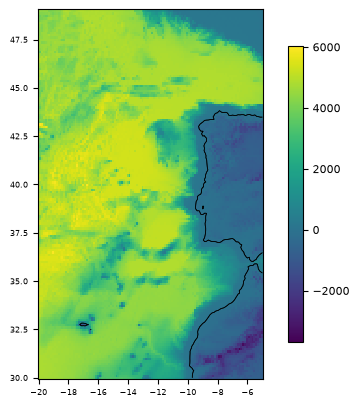

In [53]:
figure("MOW Box")
ax = gca()
pcolor(bx,by,permutedims(b, [2,1]));
colorbar(orientation="vertical", shrink=0.8).ax.tick_params(labelsize=8)
contour(bx,by,permutedims(b, [2,1]), [0, 0.1], colors="k", linewidths=.5)
ax.set_aspect(1/cos(mean(latr) * pi/180))
ax.tick_params("both",labelsize=6)

## Load the mask
It is used to delimit the variational analysis. External file provided.

In [54]:
mask_data = Dataset(mask_file, "r");
lon_mask = mask_data["lon"][:];
lat_mask = mask_data["lat"][:];
depth_mask = mask_data["depth"][:];
mask = Bool.(mask_data["mask"][:,:,:]);
close(mask_data);

@show size(mask)

size(mask) = (321, 233, 67)


(321, 233, 67)

### Cut mask at seleted horizontal lat-lon-depth box

In [55]:
start_lon_mask_index = findall(lon_mask .== lonr[1])[1]
end_lon_mask_index = findall(lon_mask .== lonr[end])[1]
start_lat_mask_index = findall(lat_mask .== latr[1])[1]
end_lat_mask_index = findall(lat_mask .== latr[end])[1]
start_depth_mask_index = findall(depth_mask .== depthr[1])[1]
end_depth_mask_index = findall(depth_mask .== depthr[3])[1]
@show size(lon_mask)
@show size(lat_mask)
@show size(depth_mask)
lon_mask = lon_mask[start_lon_mask_index: end_lon_mask_index];
lat_mask = lat_mask[start_lat_mask_index: end_lat_mask_index];
depth_mask = depth_mask[start_depth_mask_index: end_depth_mask_index];
mask = mask[start_lon_mask_index: end_lon_mask_index, start_lat_mask_index: end_lat_mask_index, start_depth_mask_index: end_depth_mask_index];
@show size(mask);

size(lon_mask) = (321,)
size(lat_mask) = (233,)
size(depth_mask) = (67,)
size(mask) = (121, 153, 3)


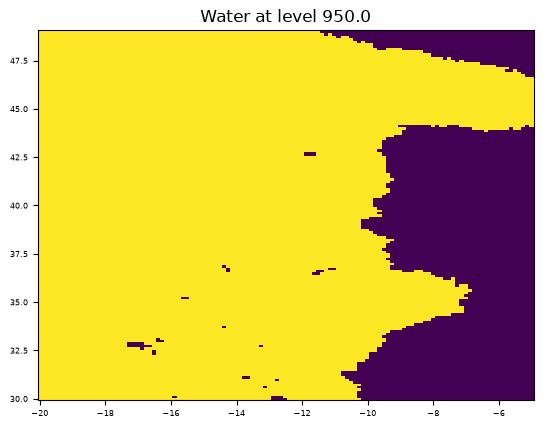

In [56]:
for level = 1: 1  # length(depth_mask)
    figure()
    ax = gca()
    #ax.set_aspect(1/cos(mean([ylim()...]) * pi/180))
    ax.tick_params("both",labelsize=6)
    pcolor(lon_mask, lat_mask, Float64.(mask[:, :, level]'));
    title("Water at level $(depthr[level])")
end

## Empty mask depth levels cut

In [57]:
mask = mask[:, :, 1: length(depth_mask)]
depthr = depthr[1: length(depth_mask)]
background_avg_profile_lenz = background_avg_profile_lenz[1: length(depth_mask)];

# Data loading

⌛⌛    
Depending on the size of your file, this step can take up to a few minutes.

In [58]:


@time obsval,obslon,obslat,obsdepth,obstime,obsids = DIVAnd.loadobs(Float64, in_file, in_variable_name);


  0.077541 seconds (550.37 k allocations: 32.434 MiB)


### Data plot
For applications with a large number of data points it is advised to first apply the `unique` function to keep only one location per profile.

In [59]:
coords = [(x,y) for (x,y) in zip(obslon, obslat)];
coords_u = unique(coords);
@info "Total number of coordinates: $(length(coords))"
@info "Number of unique coordinates (profiles): $(length(coords_u))"

[ Info: Total number of coordinates: 109814
[ Info: Number of unique coordinates (profiles): 25566


In [60]:
obslon_u = [x[1] for x in coords_u];
obslat_u = [x[2] for x in coords_u];

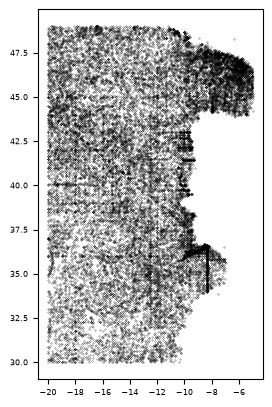

In [61]:
figure("Mediterranean-Data")
ax = subplot(1,1,1)
plot(obslon_u, obslat_u, "ko", markersize=.2)
ax.tick_params("both",labelsize=6)
ax.set_aspect(1/cos(mean(latr) * pi/180))

Check the extremal values of the observations

In [62]:
checkobs((obslon,obslat,obsdepth,obstime),obsval,obsids)

              minimum and maximum of obs. dimension 1: (-20.0, -5.0)
              minimum and maximum of obs. dimension 2: (30.0, 49.0)
              minimum and maximum of obs. dimension 3: (995.0, 1005.0)
              minimum and maximum of obs. dimension 4: (DateTime("1950-05-16T14:00:00.001"), DateTime("2025-12-31T19:42:19.999"))
                number of values equal to NaN in data: 63 [first value at index 36820 and id ]
                          minimum and maximum of data: (4.84, 15.075)


[ Info: Checking ranges for dimensions and observations


## Background analysis data selection
Global range check on data.

In [63]:
extremal_time = [DateTime(background_yearlist[1][1]), DateTime(background_yearlist[1][end] + 1)];

sel = (obslon .>= lonr[1]) .& (obslon .<= lonr[end]) .& 
      (obslat .>= latr[1]) .& (obslat .<= latr[end]) .& 
      (obsdepth .>= depthr[1]) .& (obsdepth .<= depthr[end]) .& 
      (obstime .>= extremal_time[1]) .& (obstime .<= extremal_time[2]) .& 
      (obsval .>= extremal_field[1]) .& (obsval .<= extremal_field[2]);

index = findall(sel)

@info("Selected observations: $(length(index)) out of $(length(obstime))");

obslon_bg = obslon[sel]
obslat_bg = obslat[sel]
obsdepth_bg = obsdepth[sel]
obstime_bg = obstime[sel]
obsval_bg = obsval[sel]
obsid_bg = obsids[sel];

[ Info: Selected observations: 96088 out of 109814


In [64]:
checkobs((obslon_bg,obslat_bg,obsdepth_bg,obstime_bg),obsval_bg,obsid_bg)

              minimum and maximum of obs. dimension 1: (-20.0, -5.0)
              minimum and maximum of obs. dimension 2: (30.0, 49.0)
              minimum and maximum of obs. dimension 3: (995.0, 1005.0)
              minimum and maximum of obs. dimension 4: (DateTime("1961-05-20T10:00:00"), DateTime("2020-12-31T19:08:20"))
                          minimum and maximum of data: (4.84, 15.075)


[ Info: Checking ranges for dimensions and observations


## Empty observations depth levels cut
Need to remove not completely filled levelsin mask that do not have observations to compute climatology.

In [65]:
no_observations_index = length(depthr)
while no_observations_index > 0
    sel = obsdepth_bg .== depthr[no_observations_index]
    index = findall(sel)
    if length(index) == 0
        @info "Warning: no observations found at depth layer $(depthr[no_observations_index]) m. Removing level..."
        no_observations_index -= 1
    else
        @info "Number of observations found at depth layer $(depthr[no_observations_index]) m: $(length(index))"
        break
    end
end
mask_an = mask[:, :, 1: no_observations_index]
depthr_an = depthr[1: no_observations_index]
background_avg_profile_lenz_an = background_avg_profile_lenz[1: no_observations_index];
@show size(mask_an);

size(mask_an) = (121, 153, 2)


[ Info: Warning: no observations found at depth layer 1050.0 m. Removing level...
[ Info: Number of observations found at depth layer 1000.0 m: 17628


## Metadata and attributes
Edit the different fields according to the project, the authors etc.     
This is used for the netCDF file but also for the XML needed for the Sextant catalog.

In [66]:
metadata = OrderedDict(
    # Name of the project
    "project" => project,

    # URN code for the institution EDMO registry,
    # e.g. SDN:EDMO::1579
    "institution_urn" => institution_urn,

    # Production group
    "production" => production,

    # Name and emails from authors
    "Author_e-mail" => author_email,

    # Source of the observation
    "source" => source,

    # Additional comment
    "comment" => comment,

    # SeaDataNet Vocabulary P35 URN
    # http://seadatanet.maris2.nl/v_bodc_vocab_v2/search.asp?lib=p35
    "parameter_keyword_urn" => parameter_keyword_urn,

    # List of SeaDataNet Parameter Discovery Vocabulary P02 URNs
    # http://seadatanet.maris2.nl/v_bodc_vocab_v2/search.asp?lib=p02
    "search_keywords_urn" => [search_keywords_urn],

    # List of SeaDataNet Vocabulary C19 area URNs
    # SeaVoX salt and fresh water body gazetteer (C19)
    # http://seadatanet.maris2.nl/v_bodc_vocab_v2/search.asp?lib=C19
    "area_keywords_urn" => [area_keywords_urn],

    "product_version" => product_version,
    
    "product_code" => product_code,
    
    # bathymetry source acknowledgement
    "bathymetry_source" => bathymetry_source,
    
    # NetCDF CF standard name
    # http://cfconventions.org/Data/cf-standard-names/current/build/cf-standard-name-table.html
    "netcdf_standard_name" => standard_name,

    "netcdf_long_name" => long_name,

    "netcdf_units" => units,

    # Abstract for the product
    "abstract" => abstract_name,
    
    # This option provides a place to acknowledge various types of support for the
    # project that produced the data
    "acknowledgement" => acknowledgement,

    "documentation" => documentation,

    # Digital Object Identifier of the data product
    "doi" => doi);

In [67]:
ncglobalattrib,ncvarattrib = SDNMetadata(metadata, out_file, in_variable_name, lonr, latr)

(OrderedDict("project" => "SeaDataCloud", "institution" => "Istituto Nazionale di Geofisica e Vulcanologia, Sede di Bologna", "institution_urn" => "SDN:EDMO::251", "production" => "INGV oceanography group. Emails: paolo.oliveri@ingv.it; simona.simoncelli@ingv.it; gelsomina.mattia@ingv.it", "Author_e-mail" => "Enrico Baglione <enrico.baglione@ingv.it>, Simona Simoncelli <simona.simoncelli@ingv.it, Paolo Oliveri <paolo.oliveri@ingv.it>", "source" => "observational data from SeaDataNet, CORA 5.2", "comment" => "Duplicates removal and QC applied to the integrated dataset", "parameter_keyword" => "ITS-90 water temperature", "parameter_keyword_urn" => "SDN:P35::WATERTEMP", "search_keywords" => "Temperature of the water column"…), OrderedDict("units" => "degree_C", "standard_name" => "sea_water_temperature", "long_name" => "Sea Water In Situ Temperature"))

In [68]:
ncglobalattrib = OrderedDict(
    "project" => project,
    "institution" => "Istituto Nazionale di Geofisica e Vulcanologia – Sede di Bologna",
    "institution_urn" => institution_urn,
    "production" => production,
    "Author_e-mail" => author_email,
    "source" => source,
    "comment" => comment,
    "parameter_keyword" => "ITS-90 water temperature",
    "parameter_keyword_urn" => parameter_keyword_urn,
    "search_keywords" => "Temperature of the water column",
    "search_keywords_urn" => search_keywords_urn,
    "area_keywords" => "Mediterranean Sea",
    "area_keywords_urn" => area_keywords_urn,
    "product_code" => product_code,
    "product_version" => product_version,
    "bathymetry_source" => bathymetry_source,
    "abstract" => abstract_name,
    "acknowledgement" => acknowledgement,
    "documentation" => documentation,
    "doi" => doi,
    "data_access" => "http://sdn.oceanbrowser.net/data/SeaDataCloud-domains",
    "WEB_visualisation" => "http://sdn.oceanbrowser.net/web-vis/"
);

ncvarattrib = OrderedDict(
    "units" => "degrees_C",
    "standard_name" => "sea_water_temperature",
    "long_name" => "Sea Water In Situ Temperature"
);

## Background Analysis

Remember to:
* either remove the result file before running
* or modify the name of the output file, 

otherwise you'll get the message     
```julia
NCDatasets.NetCDFError(13, "Permission denied")
```

## Correlation lengths and noise-to-signal ratio
We will use the function `diva3D` for the calculations.     
⚠ With this function, the correlation length has to be defined in meters (not in degrees).

In [69]:
sz = (length(lonr), length(latr), length(depthr_an));
background_avg_lenx = fill(20. * deg_multiplier, sz)   # Approx. 20 degrees for initial background average
background_avg_leny = fill(20. * deg_multiplier, sz)   # Approx. 20 degrees for initial background average
background_avg_lenz = permutedims(repeat(background_avg_profile_lenz_an, inner=(1, sz[1], sz[2])), (2, 3, 1));  # For background initial average
background_avg_len = (background_avg_lenx, background_avg_leny, background_avg_lenz); # For background initial average
background_lenx = fill(10 * deg_multiplier, sz)   # Approx. 10 degrees for background analysis
background_leny = fill(10 * deg_multiplier, sz)   # Approx. 10 degrees for background analysis
background_lenz = fill(0., sz);  # Vertical correlation disabled for background analysis
background_len = (background_lenx, background_leny, background_lenz);
background_epsilon2 = 12;

@show size(background_lenz);

size(background_lenz) = (121, 153, 2)


In [70]:
background_TS = DIVAnd.TimeSelectorYearListMonthList(background_yearlist, background_monthlist);
@show background_TS

background_TS = TimeSelectorYearListMonthList{Vector{UnitRange{Int64}}, Vector{UnitRange{Int64}}}(UnitRange{Int64}[1961:2020], UnitRange{Int64}[1:12])


TimeSelectorYearListMonthList{Vector{UnitRange{Int64}}, Vector{UnitRange{Int64}}}(UnitRange{Int64}[1961:2020], UnitRange{Int64}[1:12])

### Plotting function
Define a plotting function that will be applied for each time index and each depth level.     
All the figures will be saved the selected directory.

In [71]:
if !isdir(background_figures_dir)
    mkpath(background_figures_dir);
    @info "Creating directory $(background_figures_dir)"
end

In [72]:
function plotres(timeindex, sel, fit, erri)
    tmp = copy(fit)
    nx,ny,nz = size(tmp)
    for i in 1:nz
        figure("MOW analysis")
        ax = subplot(1,1,1)
        ax.tick_params("both",labelsize=6)
        ylim(minimum(latr) - dy, maximum(latr) + dy);
        xlim(minimum(lonr) - dx, maximum(lonr) + dx);
        title("Depth: $(depthr_an[i]) \n Time index: $(timeindex)", fontsize=6)
        pcolor(lonr.-dx/2.,latr.-dy/2, permutedims(tmp[:,:,i], [2,1]);
               vmin = 33, vmax = 40)
        colorbar(extend="both", orientation="vertical", shrink=0.8).ax.tick_params(labelsize=8)

        contourf(bx,by,permutedims(b,[2,1]), levels = [-1e5,0],colors = [[.5,.5,.5]])
        ax.set_aspect(1/cos(mean(latr) * pi/180))
        
        #figname = in_variable_name,:@sprintf("_%02d",i),  :@sprintf("_%03d.png",timeindex)
        figname = "test1.png"
        savefig(joinpath(background_figures_dir, figname), dpi=300, bbox_inches="tight");
        #PythonPlot.close_figs()
    end
end

plotres (generic function with 1 method)

In [73]:
#figname = "test1.png"
#joinpath(background_figures_dir, figname)

### Create background field using `diva3d`
Here only the noise-to-signal ratio is estimated.     
Set `fitcorrlen` to `true` to also optimise the correlation length.

In [74]:
### aggiunta il 2026/01/30
if isfile(background_file)
    rm(background_file)
end

[ Info: Creating netCDF file /home/marjahn.finlayson//Output/VRE/MOW_Box/annual/TEMPERATURE_background_climatology_WP.nc
[ Info: Time step 1 / 1
[ Info: scaled correlation length (min,max) in dimension 1: (1.113195e6, 1.113195e6)
[ Info: scaled correlation length (min,max) in dimension 2: (1.113195e6, 1.113195e6)
[ Info: scaled correlation length (min,max) in dimension 3: (0.0, 0.0)
[ Info: number of windows: 1


 14.101914 seconds (123.47 k allocations: 2.352 GiB, 35.29% gc time, 1.23% compilation time)


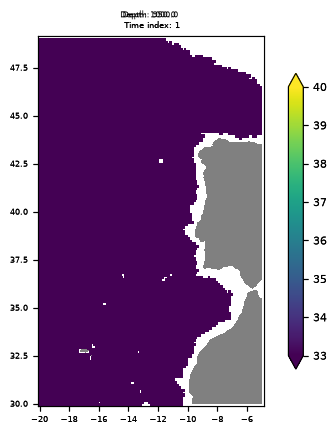

Dict{Symbol, Any} with 5 entries:
  :used               => Bool[1, 1, 1, 1, 1, 1, 1, 1, 1, 1  …  1, 1, 1, 1, 1, 1…
  :residuals          => [-0.128371, -0.148372, -0.418371, -0.258372, -0.328371…
  :mask               => Bool[1 1 … 1 1; 1 1 … 1 1; … ; 0 0 … 0 0; 0 0 … 0 0;;;…
  :factore            => [0.0385234;;]
  :background_profile => [14.8117; 9.90842;;]

In [75]:
if !isfile(background_file)
    # background analysis
    dbinfo = @time diva3d((lonr, latr, depthr_an, background_TS),
                          (obslon_bg, obslat_bg, obsdepth_bg, obstime_bg), obsval_bg,
                          background_len, background_epsilon2,
                          background_file, in_variable_name,
                          background_epsilon2_factor=1.,
                          background_lenz=background_avg_lenz,
                          bathname=bathymetry_file,
                          plotres=plotres,
                          mask=mask_an,
                          surfextend=false,
                          fitcorrlen=false,
                          ncvarattrib=ncvarattrib,
                          ncglobalattrib=ncglobalattrib,
                          solver=:direct,
                          MEMTOFIT=125,
                          filteranom=0,
                          );
end

In [76]:
dbinfo

Dict{Symbol, Any} with 5 entries:
  :used               => Bool[1, 1, 1, 1, 1, 1, 1, 1, 1, 1  …  1, 1, 1, 1, 1, 1…
  :residuals          => [-0.128371, -0.148372, -0.418371, -0.258372, -0.328371…
  :mask               => Bool[1 1 … 1 1; 1 1 … 1 1; … ; 0 0 … 0 0; 0 0 … 0 0;;;…
  :factore            => [0.0385234;;]
  :background_profile => [14.8117; 9.90842;;]

## Save the observation metadata in the NetCDF file

In [77]:
DIVAnd.saveobs(background_file,
               (obslon_bg, obslat_bg, obsdepth_bg, obstime_bg),
               obsid_bg);

# Sliding Analysis

## Data selection
Global range check on data.

In [78]:
# 2024/11/25 added by EB
print(yearlist[1][1], yearlist[1][end] )
# 20052018

19612020

In [79]:
extremal_time_an = [DateTime(yearlist[1][1]), DateTime(yearlist[1][end] + 1)];

#2025/04/07
print(yearlist[1][1], yearlist[1][end] )

sel = (obslon .>= lonr[1]) .& (obslon .<= lonr[end]) .& 
      (obslat .>= latr[1]) .& (obslat .<= latr[end]) .& 
      (obsdepth .>= depthr[1]) .& (obsdepth .<= depthr[end]) .& 
      (obstime .>= extremal_time_an[1]) .& (obstime .<= extremal_time_an[2]) .& 
      (obsval .>= extremal_field[1]) .& (obsval .<= extremal_field[2]);

index = findall(sel)

@info("Selected observations: $(length(index)) out of $(length(obstime))");

obslon_an = obslon[sel]
obslat_an = obslat[sel]
obsdepth_an = obsdepth[sel]
obstime_an = obstime[sel]
obsval_an = obsval[sel]
obsid_an = obsids[sel];

19612020

[ Info: Selected observations: 96088 out of 109814


In [80]:
checkobs((obslon_an, obslat_an, obsdepth_an ,obstime_an), obsval_an, obsid_an)

              minimum and maximum of obs. dimension 1: (-20.0, -5.0)
              minimum and maximum of obs. dimension 2: (30.0, 49.0)
              minimum and maximum of obs. dimension 3: (995.0, 1005.0)
              minimum and maximum of obs. dimension 4: (DateTime("1961-05-20T10:00:00"), DateTime("2020-12-31T19:08:20"))
                          minimum and maximum of data: (4.84, 15.075)


[ Info: Checking ranges for dimensions and observations


## Correlation lengths and noise-to-signal ratio
We will use the function `diva3D` for the calculations.     
⚠ With this function, the correlation length has to be defined in meters (not in degrees).

In [81]:
sz = (length(lonr), length(latr), length(depthr_an));
lenx = fill(2. * deg_multiplier, sz)  # Approxv. 2 degrees for analysis
leny = fill(2. * deg_multiplier, sz)  # Approx. 2 degrees for analysis
lenz = fill(0., sz);  # Vertical correlation disabled for analysis
len = (lenx, leny, lenz);
epsilon2 = 6;

@show size(background_avg_lenz);

size(background_avg_lenz) = (121, 153, 2)


## Sliding decades year list, month list and running average

In [82]:

sliding_TS = TimeSelectorYW(years, year_window, monthlist)
@show sliding_TS;

sliding_TS = TimeSelectorYearListMonthList{Vector{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}}, Vector{UnitRange{Int64}}}(StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}[1952.0:1.0:2022.0], UnitRange{Int64}[1:12])


In [83]:
if !isdir(analysis_figures_dir)
    mkpath(analysis_figures_dir);
    @info "Creating directory $(analysis_figures_dir)"
end

In [84]:
function plotres(timeindex, sel, fit, erri)
    tmp = copy(fit)
    nx,ny,nz = size(tmp)
    for i in 1:nz
        figure("Mediterranean analysis")
        ax = subplot(1,1,1)
        ax.tick_params("both",labelsize=6)
        ylim(minimum(latr) - dy, maximum(latr) + dy);
        xlim(minimum(lonr) - dx, maximum(lonr) + dx);
        title("Depth: $(depthr[i]) \n Time index: $(timeindex)", fontsize=6)
        pcolor(lonr.-dx/2.,latr.-dy/2, permutedims(tmp[:,:,i], [2,1]);
               vmin = 33, vmax = 40)
        colorbar(extend="both", orientation="vertical", shrink=0.8).ax.tick_params(labelsize=8)

        contourf(bx,by,permutedims(b,[2,1]), levels = [-1e5,0],colors = [[.5,.5,.5]])
        ax.set_aspect(1/cos(mean(latr) * pi/180))
        
        #figname = in_variable_name, :@sprintf("_%02d",i), :@sprintf("_%03d.png",timeindex)
        figname = "DIVA_Test.png"
        savefig(joinpath(analysis_figures_dir, figname), dpi=300, bbox_inches="tight");
        #PythonPlot.close_figs()
    end
end

plotres (generic function with 1 method)

## Create the gridded fields using diva3d

Here the climatology analysis is computed.

## Here is where the issue is. Just trying to test where the issue is in diva3d. 
It looks like there is a problem with the arrays between the DIVAnd.background array and the x and xi inputs. I think. I am not sure.

In [101]:
##ALMOST THERE!!!!

diva3d((lonr, latr, depthr, sliding_TS),
                      (obslon_an, obslat_an, obsdepth_an, obstime_an), obsval_an,
                      len, epsilon2,
                      out_file, in_variable_name,
                      background=DIVAnd.backgroundfile(background_file, in_variable_name, background_TS), #issue starts here but without array can't be broadcast to match destination
                      bathname=bathymetry_file,
                      #plotres=plotres,
                      #mask=mask,
                      #ncvarattrib=ncvarattrib,
                      #ncglobalattrib=ncglobalattrib,
                      #surfextend=false,
                      #fitcorrlen=false,
                      #solver=:direct,
                      #MEMTOFIT=125,
                      #filteranom=0,
                      );



[ Info: Creating netCDF file /home/marjahn.finlayson//Output/VRE/MOW_Box/annual/TEMPERATURE_sliding_climatology_WP.nc
[ Info: Time step 1 / 1
[ Info: analysis time index 1 uses the background time index 1
[ Info: scaled correlation length (min,max) in dimension 1: (222639.0, 222639.0)
[ Info: scaled correlation length (min,max) in dimension 2: (222639.0, 222639.0)
[ Info: scaled correlation length (min,max) in dimension 3: (0.0, 0.0)


LoadError: BoundsError: attempt to access 121×153×2 Array{Float64, 3} at index [1, 1, 3]

In [102]:
@show(err)

err = 1-element ExceptionStack:
LoadError: BoundsError: attempt to access 121×153×2 Array{Float64, 3} at index [1, 1, 3]
Stacktrace:
  [1] throw_boundserror(A::Array{Float64, 3}, I::Tuple{Int64, Int64, Int64})
    @ Base ./essentials.jl:15
  [2] checkbounds
    @ ./abstractarray.jl:699 [inlined]
  [3] getindex
    @ ./array.jl:928 [inlined]
  [4] getindex
    @ ./multidimensional.jl:743 [inlined]
  [5] checkresolution(mask::BitArray{3}, pmn::Tuple{Array{Float64, 3}, Array{Float64, 3}, Array{Float64, 3}}, len::Tuple{Array{Float64, 3}, Array{Float64, 3}, Array{Float64, 3}})
    @ DIVAnd /opt/ohpc/pub/libs/julia/1.12.6/julia_depot/packages/DIVAnd/kW7Vp/src/utils.jl:16
  [6] (::DIVAnd.var"#433#434"{Vector{Float64}, Dict{Any, Any}, Dict{Any, Any}, typeof(DIVAnd.distfun_m), DIVAnd.var"#backgroundfile##6#backgroundfile##7"{DIVAnd.var"#backgroundfile##8#backgroundfile##9"{TimeSelectorYearListMonthList{Vector{UnitRange{Int64}}, Vector{UnitRange{Int64}}}, Bool, CommonDataModel.CFVariable{Union{M

1-element ExceptionStack:
LoadError: BoundsError: attempt to access 121×153×2 Array{Float64, 3} at index [1, 1, 3]
Stacktrace:
  [1] throw_boundserror(A::Array{Float64, 3}, I::Tuple{Int64, Int64, Int64})
    @ Base ./essentials.jl:15
  [2] checkbounds
    @ ./abstractarray.jl:699 [inlined]
  [3] getindex
    @ ./array.jl:928 [inlined]
  [4] getindex
    @ ./multidimensional.jl:743 [inlined]
  [5] checkresolution(mask::BitArray{3}, pmn::Tuple{Array{Float64, 3}, Array{Float64, 3}, Array{Float64, 3}}, len::Tuple{Array{Float64, 3}, Array{Float64, 3}, Array{Float64, 3}})
    @ DIVAnd /opt/ohpc/pub/libs/julia/1.12.6/julia_depot/packages/DIVAnd/kW7Vp/src/utils.jl:16
  [6] (::DIVAnd.var"#433#434"{Vector{Float64}, Dict{Any, Any}, Dict{Any, Any}, typeof(DIVAnd.distfun_m), DIVAnd.var"#backgroundfile##6#backgroundfile##7"{DIVAnd.var"#backgroundfile##8#backgroundfile##9"{TimeSelectorYearListMonthList{Vector{UnitRange{Int64}}, Vector{UnitRange{Int64}}}, Bool, CommonDataModel.CFVariable{Union{Missing

In [130]:
start_time = now()  # Get the start time



if isfile(out_file)
    rm(out_file) # delete the previous analysis
    @info "Removing file $out_file"
end

# analysis with background field
dbinfo = @time diva3d((lonr, latr, depthr, sliding_TS),
                      (obslon_an, obslat_an, obsdepth_an, obstime_an), obsval_an,
                      len, epsilon2,
                      out_file, in_variable_name,
                      background=DIVAnd.backgroundfile(background_file, in_variable_name, background_TS),
                      bathname=bathymetry_file,
                      plotres=plotres,
                      mask=mask,
                      ncvarattrib=ncvarattrib,
                      ncglobalattrib=ncglobalattrib,
                      surfextend=false,
                      fitcorrlen=false,
                      solver=:direct,
                      MEMTOFIT=125,
                      filteranom=0,
                      );


end_time = now()  # Get the end time
elapsed_time = end_time - start_time  # Compute duration
#elapsed_time_minute = elapsed_time/60000
elapsed_time_minute = elapsed_time

# Save execution details to a log file
open(log_file, "w") do f
    write(f, "Program Name: $program_name\n")
    write(f, "Start Time: $start_time\n")
    write(f, "End Time: $end_time\n")
    write(f, "Elapsed Time: $elapsed_time\n")
    write(f, "Elapsed Time minute: $elapsed_time_minute\n")
end

println("Execution details saved to execution_time.log")

[ Info: Removing file /home/marjahn.finlayson/Output/VRE/MOW_Box/annual/TEMPERATURE_sliding_climatology_WP.nc
[ Info: Creating netCDF file /home/marjahn.finlayson/Output/VRE/MOW_Box/annual/TEMPERATURE_sliding_climatology_WP.nc
[ Info: Time step 1 / 1
[ Info: analysis time index 1 uses the background time index 1
[ Info: scaled correlation length (min,max) in dimension 1: (222639.0, 222639.0)
[ Info: scaled correlation length (min,max) in dimension 2: (222639.0, 222639.0)
[ Info: scaled correlation length (min,max) in dimension 3: (0.0, 0.0)


LoadError: BoundsError: attempt to access 121×153×2 Array{Float64, 3} at index [1, 1, 3]

## Save the observation metadata in the NetCDF file

In [248]:
DIVAnd.saveobs(out_file,
               (obslon_an, obslat_an, obsdepth_an, obstime_an),
               obsid_an);

# Save Processed observations

Save only processed observations for future use.

In [249]:
if isfile(observations_file)
    rm(observations_file) # delete the previous observations file
    @info "Removing file $observations_file"
end
DIVAnd.saveobs(observations_file, "$(in_variable_name)", obsval_an,
               (obslon_an, obslat_an, obsdepth_an, obstime_an), obsid_an,
               type_save = Float64,
               timeorigin = DateTime(1950,1,1,0,0,0),
               used = trues(size(obsid_an)),
               )

[ Info: Removing file /home/marjahn.finlayson/Output/VRE/MOW_Box/annual/TEMPERATURE_observations_WP.nc


# Residuals

Range of the residuals

In [250]:
resval_sliding = get(dbinfo, :residuals, 0);

LoadError: UndefVarError: `dbinfo` not defined in `Main`
Suggestion: add an appropriate import or assignment. This global was declared but not assigned.

For future analysis the residuals can also be saved.

In [251]:
if isfile(residuals_file)
    rm(residuals_file) # delete the previous analysis
    @info "Removing file $residuals_file"
end
DIVAnd.saveobs(residuals_file, "$(in_variable_name)_residual", resval_sliding,
               (obslon_an, obslat_an, obsdepth_an, obstime_an), obsid_an,
               type_save = Float64,
               timeorigin = DateTime(1950,1,1,0,0,0),
               used = trues(size(obsid_an)),
               )

LoadError: UndefVarError: `resval_sliding` not defined in `Main`
Suggestion: add an appropriate import or assignment. This global was declared but not assigned.